#Install libaries

In [ ]:
!pip install -q sdv ctgan catboost lightgbm xgboost imbalanced-learn openpyxl tensorflow

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 207.9/207.9 kB 6.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 10.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 140.0/140.0 kB 12.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 15.3/15.3 MB 86.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 52.7/52.7 kB 5.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 74.5/74.5 kB 7.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 202.3/202.3 kB 19.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.1/2.1 MB 97.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 90.1/90.1 kB 8.6 MB/s eta 0:00:00


#Import Libraries

In [ ]:
import numpy as np
import pandas as pd
import warnings
warnings.filterwarnings('ignore') # Keep thesis outputs clean

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import (
    classification_report,
    accuracy_score,
    confusion_matrix
)

import matplotlib.pyplot as plt
import seaborn as sns

# Imblearn Samplers
from imblearn.over_sampling import RandomOverSampler, SMOTE, ADASYN
from imblearn.under_sampling import RandomUnderSampler, EditedNearestNeighbours, TomekLinks
from imblearn.combine import SMOTEENN

# ML & DL Models
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, AdaBoostClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.neural_network import MLPClassifier
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier
from catboost import CatBoostClassifier
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

#Drive mount

In [ ]:
#=============================
# Google Drive Mount
#=============================

from google.colab import drive
drive.mount('/content/drive')

import joblib
import os

Mounted at /content/drive


#Path save

In [ ]:
SAVE_PATH = "/content/drive/MyDrive/Colab Notebooks/Thesis/"

os.makedirs(SAVE_PATH, exist_ok=True)

#Load Datasets

In [ ]:
print("Loading and cleaning dataset...")
CSV_PATH = "/content/drive/MyDrive/Colab Notebooks/Thesis/cirrhosis.csv"
df = pd.read_csv(CSV_PATH)

Loading and cleaning dataset...


#Cleaning data

In [ ]:
# Missing values processing
missing_tokens = ["NaNN","NANN","NAN","NaN","nan","NA",
                  "N/A","na","?","-","--"," ","", "None",
                  "null","NULL"]
df = df.replace(missing_tokens, np.nan)

In [ ]:
# Missing values fillup
obj_cols = df.select_dtypes(include="object").columns
for c in obj_cols:
    df[c] = df[c].astype(str).str.strip()
    df.loc[df[c].isin(["", "nan", "NaN", "NAN",
                       "NaNN", "None", "NULL", "null"]), c] = np.nan

In [ ]:
# Drop Duplicates
df = df.drop_duplicates().reset_index(drop=True)

#Mapping

In [ ]:
# Mapping
mapping = {
    'Ascites': {'Y': 1, 'N': 0},
    'Hepatomegaly': {'Y': 1, 'N': 0},
    'Spiders': {'Y': 1, 'N': 0},
    'Edema': {'N': 0, 'S': 2, 'Y': 1},
    'Status': {'D': 0, 'C': 1, 'CL': 2},
    'Drug': {'D-penicillamine': 0, 'Placebo': 1},
    'Sex': {'M': 0, 'F': 1}
}
df = df.replace(mapping)

In [ ]:
# Drop null values in Target
df = df.dropna(subset=["Status"]).copy()
if df["Status"].dtype == "object":
    df["Status"] = df["Status"].map({'D': 0, 'C': 1, 'CL': 2})
df["Status"] = df["Status"].astype(int)

In [ ]:
# Remove CL class (Class 2) for binary classification as per your previous requirement
df = df[df["Status"] != 2].reset_index(drop=True)

#Train test split

In [ ]:
#Preprocessing
print("Splitting and preprocessing features...")
X = df.drop(columns=["Status"])
y = df["Status"]

Splitting and preprocessing features...


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

In [ ]:
X_train.shape


(314, 19)

#Save drive to test datasts at csv

In [ ]:
#====================================
# Save Test Dataset
#====================================

X_test.to_csv(
    SAVE_PATH + "/X_test.csv",
    index=False
)

print("X_test Saved Successfully")

X_test Saved Successfully


In [ ]:
y_test.to_csv(
    SAVE_PATH + "/y_test.csv",
    index=False
)

print("y_test Saved Successfully")

y_test Saved Successfully


#Check data befor sampling

In [ ]:

print(" DATA DISTRIBUTION BEFORE SAMPLING ")

print(f"Total Train Data: {len(y_train)}")
print("Train Data Class Counts:")
for cls, count in y_train.value_counts().items():
    print(f"  Class {cls}: {count} samples")

print(f"\nTotal Test Data: {len(y_test)}")

print("Test Data Class Counts:")

for cls, count in y_test.value_counts().items():
    print(f"  Class {cls}: {count} samples")



 DATA DISTRIBUTION BEFORE SAMPLING 
Total Train Data: 314
Train Data Class Counts:
  Class 1: 185 samples
  Class 0: 129 samples

Total Test Data: 79
Test Data Class Counts:
  Class 1: 47 samples
  Class 0: 32 samples


In [ ]:
num_cols = X.select_dtypes(include=np.number).columns.tolist()
cat_cols = [c for c in X.columns if c not in num_cols]

In [ ]:
preprocess = ColumnTransformer(
    transformers=[
        ("num", Pipeline([("imputer",
                           SimpleImputer(strategy="median"))]),
          num_cols),
        ("cat", Pipeline([
            ("imputer",
             SimpleImputer(strategy="most_frequent")),
            ("ohe",
             OneHotEncoder(handle_unknown="ignore",
                           sparse_output=False))
        ]), cat_cols),
    ],
    remainder="drop"
)


In [ ]:
X_train_proc = preprocess.fit_transform(X_train)
X_test_proc  = preprocess.transform(X_test)


In [ ]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_proc)
X_test_scaled  = scaler.transform(X_test_proc)

In [ ]:
X_train_scaled.shape

(314, 19)

#CUSTOM GENERATIVE WRAPPER

In [ ]:
# =========================================================
# CUSTOM GENERATIVE WRAPPER
# =========================================================
class GenerativeSampler:
    """Wrapper to make CTGAN, TVAE, and CopulaGAN behave like imblearn samplers"""
    def __init__(self, model_name='CTGAN', samples=500, epochs=50):
        self.model_name = model_name
        self.samples = samples
        self.epochs = epochs

    def fit_resample(self, X, y):
        # Convert numpy back to temporary dataframe for SDV processing
        temp_df = pd.DataFrame(X, columns=[str(i) for i in range(X.shape[1])])
        temp_df['target'] = y.values if hasattr(y, 'values') else y

        if self.model_name == 'CTGAN':
            from ctgan import CTGAN
            model = CTGAN(
                epochs=self.epochs,
                verbose=False
                )
            model.fit(temp_df, discrete_columns=['target'])
            syn_data = model.sample(self.samples)

        elif self.model_name in ['TVAE', 'CopulaGAN']:
            from sdv.metadata import SingleTableMetadata
            metadata = SingleTableMetadata()
            metadata.detect_from_dataframe(temp_df)

            if self.model_name == 'TVAE':
                from sdv.single_table import TVAESynthesizer
                model = TVAESynthesizer(metadata,
                                        epochs=self.epochs
                                        )
            else:
                from sdv.single_table import CopulaGANSynthesizer
                model = CopulaGANSynthesizer(metadata,
                                             epochs=self.epochs
                                             )

            model.fit(temp_df)
            syn_data = model.sample(num_rows=self.samples)

        # Append synthetic rows to original training data
        combined = pd.concat([temp_df, syn_data], ignore_index=True)
        return combined.drop(columns=['target']).values, combined['target'].values

#Sampling Function

In [ ]:
!pip install imbalanced-learn

In [ ]:
#Sampling Function

samplers = {
    "RAW": None,
    "ROS": RandomOverSampler(random_state=42),
    "RUS": RandomUnderSampler(random_state=42),
    "SMOTE": SMOTE(random_state=42),
    "ADASYN": ADASYN(random_state=42),
    "ENN": EditedNearestNeighbours(),
    "TOMEK": TomekLinks(),
    "SMOTEENN": SMOTEENN(random_state=42),
    "SMOTENC": SMOTE(random_state=42),
    "CTGAN": GenerativeSampler(model_name='CTGAN',
                               samples=500,
                               epochs=50
                               ),
    "TVAE": GenerativeSampler(model_name='TVAE',
                              samples=500,
                              epochs=50
                              ),
    "CopulaGAN": GenerativeSampler(model_name='CopulaGAN',
                                   samples=500,
                                   epochs=50
                                   )
}


In [ ]:
sampled_datasets = {}

In [ ]:
for name, sampler in samplers.items():
    print(f"Applying {name}...")
    if sampler is None:
        sampled_datasets[name] = (X_train_scaled, y_train)

        # ---------------------------------------------------------
        # Print Data Distribution AFTER Sampling (RAW)
        # ---------------------------------------------------------
        print(f"[Class Distribution AFTER {name} on Train Data]:")
        classes, counts = np.unique(y_train, return_counts=True)
        for cls, count in zip(classes, counts):
            print(f"Class {cls}: {count} samples")

    else:
        try:
            X_res, y_res = sampler.fit_resample(X_train_scaled, y_train)
            sampled_datasets[name] = (X_res, y_res)

            # ---------------------------------------------------------
            # Print Data Distribution AFTER Sampling
            # ---------------------------------------------------------
            print(f"[Class Distribution AFTER {name} on Train Data]:")
            classes, counts = np.unique(y_res, return_counts=True)
            for cls, count in zip(classes, counts):
                print(f"      Class {cls}: {count} samples")

        except Exception as e:
            print(f"    [Skipped] {name} encountered an error: {e}")
print("\n")

Applying RAW...
[Class Distribution AFTER RAW on Train Data]:
Class 0: 129 samples
Class 1: 185 samples
Applying ROS...
[Class Distribution AFTER ROS on Train Data]:
      Class 0: 185 samples
      Class 1: 185 samples
Applying RUS...
[Class Distribution AFTER RUS on Train Data]:
      Class 0: 129 samples
      Class 1: 129 samples
Applying SMOTE...
[Class Distribution AFTER SMOTE on Train Data]:
      Class 0: 185 samples
      Class 1: 185 samples
Applying ADASYN...
[Class Distribution AFTER ADASYN on Train Data]:
      Class 0: 174 samples
      Class 1: 185 samples
Applying ENN...
[Class Distribution AFTER ENN on Train Data]:
      Class 0: 129 samples
      Class 1: 105 samples
Applying TOMEK...
[Class Distribution AFTER TOMEK on Train Data]:
      Class 0: 129 samples
      Class 1: 170 samples
Applying SMOTEENN...
[Class Distribution AFTER SMOTEENN on Train Data]:
      Class 0: 117 samples
      Class 1: 99 samples
Applying SMOTENC...
[Class Distribution AFTER SMOTENC on Trai

#Save SMOTENC sampling data

In [ ]:
#====================================
# Save SMOTENC Sampled Dataset
#====================================

X_train_SMOTENC = sampled_datasets["SMOTENC"][0]
y_train_SMOTENC = sampled_datasets["SMOTENC"][1]

joblib.dump(
    X_train_SMOTENC,
    SAVE_PATH+"/X_train_SMOTENC.pkl"
)

joblib.dump(
    y_train_SMOTENC,
    SAVE_PATH+"/y_train_SMOTENC.pkl"
)

print("SMOTENC Dataset Saved Successfully")

SMOTENC Dataset Saved Successfully


#Save datasets to pandas

In [ ]:
# ===============================
# Save as Pandas CSV
# ===============================
import pandas as pd

X_train_df = pd.DataFrame(X_train_SMOTENC)
X_train_df.to_csv(
    SAVE_PATH + "/X_train_SMOTENC.csv",
    index=False
)

y_train_df = pd.DataFrame(y_train_SMOTENC, columns=["Status"])
y_train_df.to_csv(
    SAVE_PATH + "/y_train_SMOTENC.csv",
    index=False
)

print("SMOTENC Dataset Saved Successfully")

SMOTENC Dataset Saved Successfully


#Define Models

In [ ]:
# =========================================================
# DEFINE MODELS & METRICS (.2f FORMATTING)
# =========================================================
def get_metrics(model_name, sampling_name, y_true, y_pred):
    rep = classification_report(y_true, y_pred, output_dict=True, zero_division=0)
    return {
        "Model": model_name,
        "Sampling_Method": sampling_name,
        "Overall_Accuracy": round(accuracy_score(y_true, y_pred), 2),
        "Death (0)": round(rep.get("0", {}).get("recall", 0), 2),
        "Censored (1)": round(rep.get("1", {}).get("recall", 0), 2),
    }

ml_models = {
    "RandomForest": RandomForestClassifier(n_estimators=200,
                                           class_weight='balanced',
                                           random_state=42,
                                           n_jobs=-1),
    "DecisionTree": DecisionTreeClassifier(class_weight='balanced',
                                           random_state=42),
    "GaussianNB": GaussianNB(),
    "GradientBoosting": GradientBoostingClassifier(random_state=42),
    "LightGBM": LGBMClassifier(class_weight='balanced',
                               random_state=42,
                               n_estimators=200,
                               verbose=-1),
    "XGBoost": XGBClassifier(random_state=42,
                             n_estimators=200,
                             eval_metric="mlogloss",
                             n_jobs=-1),
    "AdaBoost": AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=3,
                                                                    class_weight='balanced'), learning_rate=0.1, n_estimators=100, random_state=42),
    "CatBoost": CatBoostClassifier(random_state=42,
                                   auto_class_weights='Balanced',
                                   verbose=0, iterations=200,
                                   loss_function="MultiClass"),
    "MLP": MLPClassifier(random_state=42,
                                    hidden_layer_sizes=(128, 64),
                                    max_iter=600)
}

In [ ]:
# =========================================================
# TRAIN & EVALUATE
# =========================================================
print("Training ML and DL Models...")
#Store Confusion metrices
confusion_results ={}

all_results = []

for sample_name, (X_train_s, y_train_s) in sampled_datasets.items():

    # Train Machine Learning Models
    for model_name, model in ml_models.items():
        model.fit(X_train_s, y_train_s)

        #Save the model of GradientBoosting
        if model_name == "GradientBoosting" and sample_name =="SMOTENC":
          joblib.dump(
              model,
              SAVE_PATH+"/GradientBoosting.pkl"
          )
          print("GradientBoosting Model Saved Successfully")



        y_pred = model.predict(X_test_scaled)

        if model_name == "CatBoost":
            y_pred = np.array(y_pred).reshape(-1).astype(int)
        all_results.append(get_metrics(model_name, sample_name, y_test, y_pred))

        # Save confusion matrix
        cm = confusion_matrix(y_test, y_pred)
        confusion_results[f"{model_name}_{sample_name}"] = cm

    # Train Deep Learning Models
    num_classes = len(np.unique(y_train))
    y_train_oh = keras.utils.to_categorical(y_train_s, num_classes=num_classes)

    # ANN
    ann = keras.Sequential([
        layers.Input(shape=(X_train_s.shape[1],)),
        layers.Dense(64, activation="relu"),
        layers.Dense(num_classes, activation="softmax")
    ])
    ann.compile(optimizer="adam",
                loss="categorical_crossentropy",
                metrics=["accuracy"])
    ann.fit(X_train_s,
            y_train_oh,
            epochs=40,
            batch_size=32,
            verbose=0)
    #confutions update
    ann_pred = np.argmax(
                ann.predict(X_test_scaled, verbose=0),
                 axis=1
          )

    confusion_results[f"ANN_{sample_name}"] = confusion_matrix(
                        y_test,
                        ann_pred
           )

    all_results.append(
             get_metrics(
                "ANN",
             sample_name,
             y_test,
            ann_pred
              )
                  )
    all_results.append(get_metrics("ANN", sample_name,
                                   y_test,
                                   np.argmax(ann.predict(X_test_scaled,
                                                         verbose=0),
                                              axis=1)))

    # DNN
    dnn = keras.Sequential([
        layers.Input(shape=(X_train_s.shape[1],)),
        layers.Dense(256, activation="relu"), layers.Dropout(0.3),
        layers.Dense(128, activation="relu"), layers.Dropout(0.2),
        layers.Dense(64, activation="relu"),
        layers.Dense(num_classes, activation="softmax")
    ])
    dnn.compile(optimizer="adam",
                loss="categorical_crossentropy",
                metrics=["accuracy"])
    dnn.fit(X_train_s,
            y_train_oh,
            epochs=50,
            batch_size=32,
            verbose=0)

    dnn_pred = np.argmax(
         dnn.predict(X_test_scaled, verbose=0),
           axis=1
            )

    confusion_results[f"DNN_{sample_name}"] = confusion_matrix(
            y_test,
             dnn_pred
              )

    all_results.append(
              get_metrics(
                "DNN",
              sample_name,
                y_test,
              dnn_pred
           )
            )
    all_results.append(get_metrics("DNN",
                                   sample_name,
                                   y_test, np.argmax(dnn.predict(X_test_scaled,
                                                                 verbose=0), axis=1)))

    # 1D CNN
    X_train_cnn = X_train_s.reshape(X_train_s.shape[0],
                                    X_train_s.shape[1], 1)
    X_test_cnn  = X_test_scaled.reshape(X_test_scaled.shape[0],
                                        X_test_scaled.shape[1], 1)
    cnn = keras.Sequential([
        layers.Input(shape=(X_train_cnn.shape[1], 1)),
        layers.Conv1D(32, kernel_size=3, activation="relu"), layers.MaxPooling1D(pool_size=2),
        layers.Conv1D(64, kernel_size=3, activation="relu"), layers.GlobalMaxPooling1D(),
        layers.Dense(64, activation="relu"),
        layers.Dense(num_classes, activation="softmax")
    ])
    cnn.compile(optimizer="adam",
                loss="categorical_crossentropy",
                metrics=["accuracy"])
    cnn.fit(X_train_cnn,
            y_train_oh,
            epochs=50,
            batch_size=32,
            verbose=0)

    cnn_pred = np.argmax(
           cnn.predict(X_test_cnn, verbose=0),
           axis=1
       )

    confusion_results[f"1D_CNN_{sample_name}"] = confusion_matrix(
            y_test,
            cnn_pred
               )

    all_results.append(
            get_metrics(
              "1D_CNN",
              sample_name,
             y_test,
             cnn_pred
             )
              )
    all_results.append(get_metrics("1D_CNN", sample_name,
                                   y_test,
                                   np.argmax(cnn.predict(X_test_cnn, verbose=0), axis=1)))


Training ML and DL Models...


GradientBoosting Model Saved Successfully


#FORMAT & EXPORT RESULTS

In [ ]:
final_df = pd.DataFrame(all_results)

In [ ]:
sampling_order = ["RAW", "ROS", "RUS", "SMOTE", "ADASYN",
                  "ENN", "TOMEK", "SMOTEENN", "SMOTENC",
                  "CTGAN", "TVAE", "CopulaGAN"]


final_df['Sampling_Method'] = pd.Categorical(final_df['Sampling_Method'],
                                             categories=sampling_order,
                                             ordered=True)


final_df = final_df.sort_values(by=["Model",
                                    "Sampling_Method"]).reset_index(drop=True)

In [ ]:
pd.set_option('display.float_format', lambda x: '%.2f' % x)

In [ ]:


print("THESIS FINAL RESULTS WITH GANS")


display(final_df)

THESIS FINAL RESULTS WITH GANS


,Model,Sampling_Method,Overall_Accuracy,Death (0),Censored (1)
0,1D_CNN,RAW,0.82,0.66,0.94
1,1D_CNN,RAW,0.82,0.66,0.94
2,1D_CNN,ROS,0.77,0.66,0.85
3,1D_CNN,ROS,0.77,0.66,0.85
4,1D_CNN,RUS,0.76,0.72,0.79
...,...,...,...,...,...
175,XGBoost,SMOTEENN,0.81,0.81,0.81
176,XGBoost,SMOTENC,0.89,0.81,0.94
177,XGBoost,CTGAN,0.94,0.84,1.00
178,XGBoost,TVAE,0.89,0.84,0.91


#Save The  file


In [ ]:
final_df.to_csv("Thesis_Final_Generative_Results.csv", index=False)
final_df.to_excel("Thesis_Final_Generative_Results.xlsx", index=False)

print("\nFiles successfully saved to disk as 'Thesis_Final_Generative_Results.csv' and '.xlsx'")


Files successfully saved to disk as 'Thesis_Final_Generative_Results.csv' and '.xlsx'


In [ ]:
data = pd.read_csv("/content/Thesis_Final_Generative_Results.csv")
data.head(50)

,Model,Sampling_Method,Overall_Accuracy,Death (0),Censored (1)
0,1D_CNN,RAW,0.82,0.66,0.94
1,1D_CNN,RAW,0.82,0.66,0.94
2,1D_CNN,ROS,0.77,0.66,0.85
3,1D_CNN,ROS,0.77,0.66,0.85
4,1D_CNN,RUS,0.76,0.72,0.79
5,1D_CNN,RUS,0.76,0.72,0.79
6,1D_CNN,SMOTE,0.81,0.75,0.85
7,1D_CNN,SMOTE,0.81,0.75,0.85
8,1D_CNN,ADASYN,0.72,0.81,0.66
9,1D_CNN,ADASYN,0.72,0.81,0.66


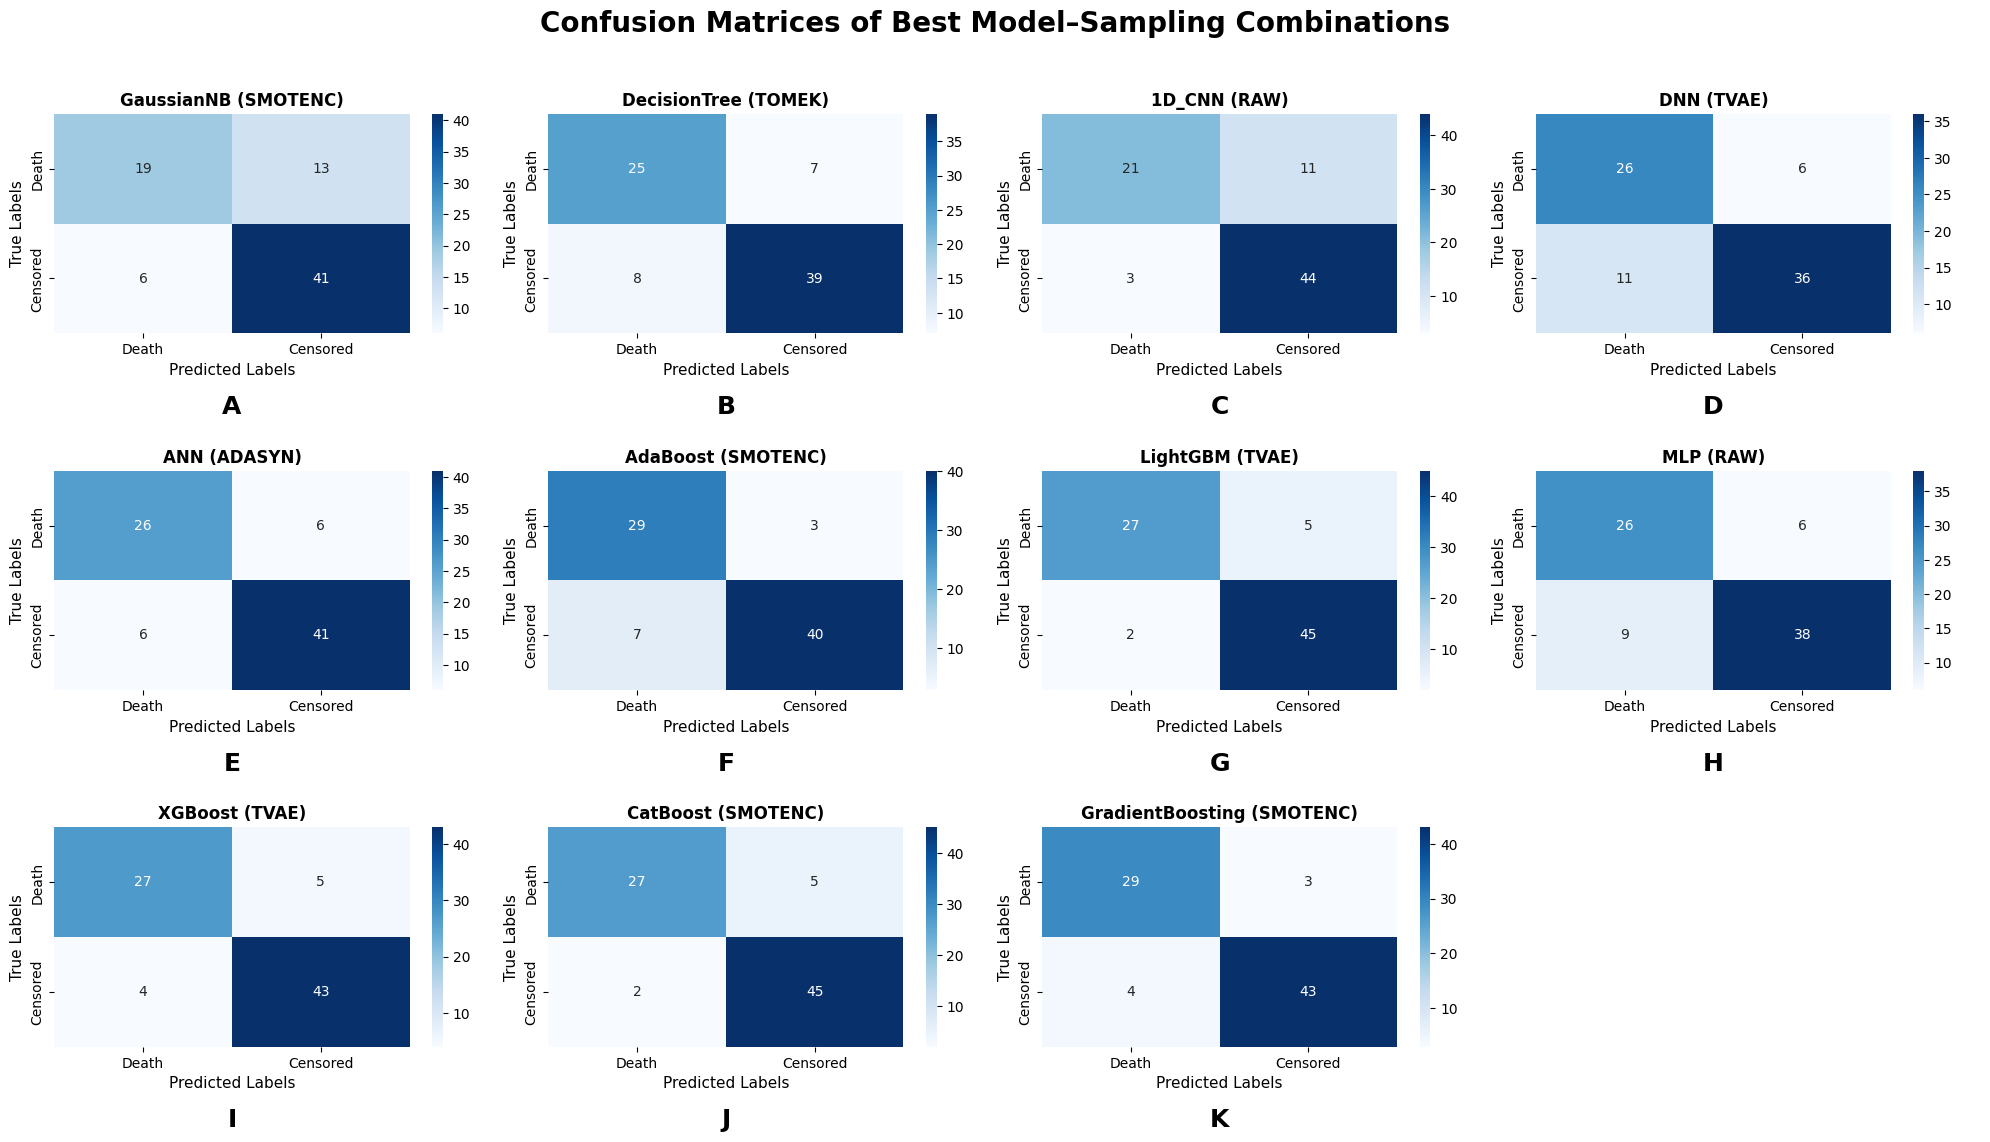

In [ ]:
import string
import matplotlib.pyplot as plt
import seaborn as sns

selected_results = {
    "GaussianNB": "SMOTENC",
    "DecisionTree": "TOMEK",
    "1D_CNN": "RAW",
    "DNN": "TVAE",
    "ANN": "ADASYN",
    "AdaBoost": "SMOTENC",
    "LightGBM": "TVAE",
    "MLP": "RAW",
    "XGBoost": "TVAE",
    "CatBoost": "SMOTENC",
    "GradientBoosting": "SMOTENC"
}

# A, B, C, D
letters = list(string.ascii_uppercase)

fig, axes = plt.subplots(3, 4, figsize=(20, 12))
axes = axes.flatten()

for i, (model_name, sample_name) in enumerate(selected_results.items()):

    key = f"{model_name}_{sample_name}"

    if key not in confusion_results:
        continue

    sns.heatmap(
        confusion_results[key],
        annot=True,
        fmt="d",
        cmap="Blues",
        cbar=True,
        ax=axes[i],
        xticklabels=["Death", "Censored"],
        yticklabels=["Death", "Censored"]
    )

    # Model name
    #axes[i].set_title(model_name, fontsize=14, fontweight="bold")
    axes[i].set_title(
    f"{model_name} ({sample_name})",
    fontsize=12,
    fontweight="bold"
)

    # Axis labels
    axes[i].set_xlabel("Predicted Labels", fontsize=11)
    axes[i].set_ylabel("True Labels", fontsize=11)

    # Letter (A, B, C...) below each subplot
    axes[i].text(
        0.5,
        -0.28,
        letters[i],
        transform=axes[i].transAxes,
        ha="center",
        va="top",
        fontsize=18,
        fontweight="bold"
    )

# Hide unused subplot
for j in range(len(selected_results), len(axes)):
    axes[j].axis("off")

plt.suptitle(
    "Confusion Matrices of Best Model–Sampling Combinations",
    fontsize=20,
    fontweight="bold"
)

plt.tight_layout(rect=[0, 0.02, 1, 0.96])

plt.savefig(
    SAVE_PATH + "/Result_Analysis_Confusion_Matrix.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()